Tested with:
- Python 3.13.9
- numpy 2.4.4
- pandas 2.3.3
- scikit-learn 1.7.2
- rdkit 2026.3.1
- ase 3.26.0
- scikit-activeml 1.0.0
- skorch 1.3.1

Visualisation:
- umap-learn 0.5.12
- datashader 0.19.1
- bokeh 3.9.0
- holoviews 1.22.1
- scikit-image 0.26.0
- colorcet 3.2.1

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pprint  # Pretty print data structures
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib
import skactiveml
import matplotlib.ticker as ticker
from joblib import Parallel, delayed
from rdkit import Chem
from rdkit.Chem import AllChem, Descriptors, MACCSkeys, rdMolDescriptors, rdFingerprintGenerator
from rdkit.ML.Descriptors import MoleculeDescriptors
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error, mean_squared_error
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.model_selection import learning_curve
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.base import clone
from mpl_toolkits.axes_grid1 import make_axes_locatable
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, VotingRegressor
from sklearn.kernel_ridge import KernelRidge
from sklearn.kernel_approximation import Nystroem # Approximate a kernel map using a subset of the training data, KRR on QM9 is computationally infeasible
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor
from skactiveml.regressor import SklearnRegressor
from skactiveml.pool import RandomSampling, QueryByCommittee, TypiClust
from skactiveml.utils import MISSING_LABEL, labeled_indices, unlabeled_indices, call_func
plt.style.use('ggplot')  # Set Matplotlib style to 'ggplot'

# Config
CSV_PATH = '../data/qm9/raw/gdb9.sdf.csv'
SDF_PATH = '../data/qm9/raw/gdb9.sdf'
SMILES_COL = 'smiles'
TARGET_COL = 'gap'
MORGAN_RADIUS = 2
MORGAN_BITS = 2048

# Do NOT include 'homo' or 'lumo' here — gap = lumo - homo (leakage!)
# Do NOT include thermodynamic properties u0, u298, h298, g298, if one of them is target
BLACKLIST_COLS = [SMILES_COL, TARGET_COL, 'mol_id', 'Unnamed: 0', 'mol', 'lumo', 'homo']
qm9_features_full = ['mu', 'alpha', 'homo', 'lumo', 'gap', 'zpve', 'u0', 'u298', 'h298', 'g298', 'cv']
qm9_features = [c for c in qm9_features_full if c not in BLACKLIST_COLS]

def fps_from_smiles(smiles):
    '''
    Build one RDKit molecule from SMILES and compute Moragan and MACCSkeys fingerprints.

    Args:
        smiles: SMILES string (str).
    '''
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f'Invalid SMILES: {smiles}')

    gen = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS, fpSize=MORGAN_BITS) #create Morgan generator
    
    morgan_fp = np.array(gen.GetFingerprintAsNumPy(mol), dtype=np.float32)
    maccs_fp = np.array(MACCSkeys.GenMACCSKeys(mol), dtype=np.float32)
    
    return morgan_fp, maccs_fp

def compute_fingerprints_parallel(smiles_list, n_jobs=-1):
    '''
    Compute Morgan + MACCS fingerprints in parallel.

    Args:
        smiles_list: list of SMILES strings (list[str])
        n_jobs: number of worker processes (-1 = all cores)

    Returns:
        morgan: np.ndarray
        maccs: np.ndarray
    '''
    fps = Parallel(n_jobs=n_jobs, backend='loky', batch_size='auto')(delayed(fps_from_smiles)(smiles) for smiles in smiles_list)

    morgan, maccs = zip(*fps)
    return np.stack(morgan), np.stack(maccs)
    
def build_X(df, scaler=StandardScaler(), train=False, raw=False, n_jobs=-1):
    '''
    Build X with scaled continuous part and fingerprints.

    Args:
        df: dataframe with a 'smiles' column and qm9_features columns
        scaler: fitted scaler, or None to create a StandardScaler
        train: if True, fit scaler on continuous features
        raw: if True, return unscaled X
        n_jobs: number of CPU cores to use for fingerprinting (-1 = all)

    Returns:
        X: feature matrix
    '''
    df = df.copy()
    smiles_list = df['smiles'].tolist()    
    morgan, maccs = compute_fingerprints_parallel(smiles_list, n_jobs=n_jobs)
    continuous = df[qm9_features].to_numpy()

    if raw:
        return np.hstack([continuous, morgan, maccs])

    continuous = (
        scaler.fit_transform(continuous)
        if train
        else scaler.transform(continuous)
    )

    return np.hstack([continuous, morgan, maccs])

def plot_prediction(X, y, model, model_name=None, name=TARGET_COL, figsize=(6, 6), save=None, format='pdf'):
    '''
    Plot predictions for the given model and data.

    Args:
        X : Input features (np.array).
        y : True target values (np.array).
        model: Fitted model.
        model_name: Name of the model (str).
        name: Name of the target value (str).
        figsize: Figure size (tuple).
        save: Save path (str).
        format: Save format (str).
    '''
    y_true = y*27.2114
    y_pred = model.predict(X)*27.2114
    errors = np.abs(y_true - y_pred)
    fig, ax = plt.subplots(figsize=figsize)
    
    sc = ax.scatter(y_true, y_pred, c=errors, cmap='viridis', label='predicted values')    
    ax.plot(y_true, y_true, 'r-', label='true values')
    
    ax.set_xlabel(f'True Value (eV)', fontsize=14)
    ax.set_ylabel(f'Predicted Value (eV)', fontsize=14)
    ax.legend(facecolor='white', fontsize=12)
    ax.set_aspect('equal', adjustable='box')
    # if model_name is None:
    #     ax.set_title(f'{model.__class__.__name__} prediction plot\n{name}', fontsize=16)
    # else:
    #     ax.set_title(f'{model_name} prediction plot\n{name}', fontsize=16)

    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='5%', pad=0.15)
    cbar = fig.colorbar(sc, cax=cax)
    cbar.set_label('Absolute Error (eV)', fontsize=14)

    plt.tight_layout()
    
    if save is not None:
        fig.savefig(save, format=format, dpi=300)
    plt.show()
    print('Training scores:')
    print(f'MAE = {mean_absolute_error(y_true,y_pred):.4f}')
    print(f'MSE = {mean_squared_error(y_true,y_pred):.4f}')
    print(f'RMSE = {root_mean_squared_error(y_true,y_pred):.4f}')
    print(f'r^2 = {r2_score(y_true,y_pred):.4f}')

def print_cross_val(X, y, model, splits=5, random_state=42):
    '''
    Print cross validation scores for the given model and data.

    Args:
        X : Input features (np.array).
        y : True target values (np.array).
        model: Fitted model.
        n_splits: Number of CV splits (int).
        random_state: Random state seed (int).
    '''
    n_cont = len(qm9_features) + len(rdkit_features)
    preprocessor = ColumnTransformer([
        ('scaler',       StandardScaler(), list(range(n_cont))),
        ('fingerprints', 'passthrough',    list(range(n_cont, X.shape[1]))),
    ])

    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model),
    ])

    cv = KFold(n_splits=splits, shuffle=True, random_state=random_state)
    scoring_metrics = {
        'mae':  'neg_mean_absolute_error',
        'mse':  'neg_mean_sqared_error',
        'rmse': 'neg_root_mean_squared_error',
        'r2':   'r2',
    }
    results = cross_validate(pipe, X, y, cv=cv, scoring=scoring_metrics)

    print('Cross-validation scores:')
    print(f'Mean MAE  = {np.mean(np.abs(results['test_mae'])):.4f}')
    print(f'Mean MSE  = {np.mean(np.abs(results['test_mse'])):.4f}')
    print(f'Mean RMSE = {np.mean(np.abs(results['test_rmse'])):.4f}')
    print(f'Mean R²   = {np.mean(results['test_r2']):.4f}')

In [11]:
# Stratified split (HOMO-LUMO gap)
df = pd.read_csv('../data/qm9/qm9small.csv')

# 1. Split 80% train, 20% temp
strat_bins = pd.qcut(df['gap'], q=10, labels=False)
df_train, df_temp = train_test_split(df, test_size=0.2, stratify=strat_bins, random_state=42)

# 2. Split temp 50/50 to get 10% test, 10% val
temp_bins = pd.qcut(df_temp['gap'], q=10, labels=False)
df_test, df_val = train_test_split(df_temp, test_size=0.5, random_state=42, stratify=temp_bins)

# 3. Save to disk
df_train.to_csv('../data/qm9/gap/qm9small_gap_train.csv', index=False)
df_test.to_csv('../data/qm9/gap/qm9small_gap_test.csv', index=False)
df_val.to_csv('../data/qm9/gap/qm9small_gap_val.csv', index=False)

In [2]:
# Load
df_train = pd.read_csv('../data/qm9/gap/qm9small_gap_train.csv')
df_test = pd.read_csv('../data/qm9/gap/qm9small_gap_test.csv')
df_val = pd.read_csv('../data/qm9/gap/qm9small_gap_val.csv')

X_train = build_X(df_train, train=True)
X_test = build_X(df_test)
X_val = build_X(df_val)

y_train = df_train[TARGET_COL].values
y_test = df_test[TARGET_COL].values
y_val = df_val[TARGET_COL].values

print(f'Train set Molecules: {X_train.shape[0]}  |  Features: {X_train.shape[1]}')
print(f'Test set Molecules: {X_test.shape[0]}  |  Features: {X_test.shape[1]}')
print(f'Validate set Molecules: {X_val.shape[0]}  |  Features: {X_val.shape[1]}')

Train set Molecules: 5356  |  Features: 2223
Test set Molecules: 669  |  Features: 2223
Validate set Molecules: 670  |  Features: 2223


## Baseline

### Train models

In [3]:
rf = RandomForestRegressor(
    n_estimators=100,
    max_features='sqrt',
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=42,
)

# kr = Pipeline([
#     ('nystroem', Nystroem(
#         kernel='laplacian', 
#         n_components=2500,
#         gamma=0.01,          # This is the most important hyperparameter to tune
#         n_jobs=-1,
#         random_state=42,
#     )),
#     ('ridge', Ridge(alpha=0.01))
# ])

kr = KernelRidge(
    alpha=0.01,
    gamma=0.01,
    kernel='laplacian',
)

xgb = XGBRegressor(
    booster='gbtree',
    colsample_bytree=0.6,
    learning_rate=0.1,
    max_depth=4,
    min_child_weight=3,
    n_estimators=100,
    reg_alpha=0.1,
    reg_lambda=1.0,
    subsample=0.8,
    n_job=-1,
)

com = VotingRegressor(
    estimators=[
        ('rf', clone(rf)),
        ('xgb', clone(xgb)),
        ('kr', clone(kr)),
    ],
    n_jobs=-1,
)

com.fit(X_train,y_train)
joblib.dump(com, 'models/qm9small/com_gap_qm9small.pkl')

['models/qm9small/com_gap_qm9small.pkl']

### Load models

In [4]:
com= joblib.load('models/qm9small/com_gap_qm9small.pkl') #Committee VotingRegressor of models above

true_test = y_test*27.2114
true_val = y_val*27.2114
com_pred_test = com.predict(X_test)*27.2114
com_pred_val = com.predict(X_val)*27.2114
com_score = {
    'mae_test': mean_absolute_error(true_test, com_pred_test),
    'rmse_test': root_mean_squared_error(true_test, com_pred_test),
    'r2_test': r2_score(true_test, com_pred_test),
    'mae_val': mean_absolute_error(true_val, com_pred_val),
    'rmse_val': root_mean_squared_error(true_val, com_pred_val),
    'r2_val': r2_score(true_val, com_pred_val),
}
print(com_score)

{'mae_test': 0.30326330815429436, 'rmse_test': 0.38670457944600806, 'r2_test': 0.9067405215693447, 'mae_val': 0.3206142602531512, 'rmse_val': 0.4085013260656805, 'r2_val': 0.8992604495717543}


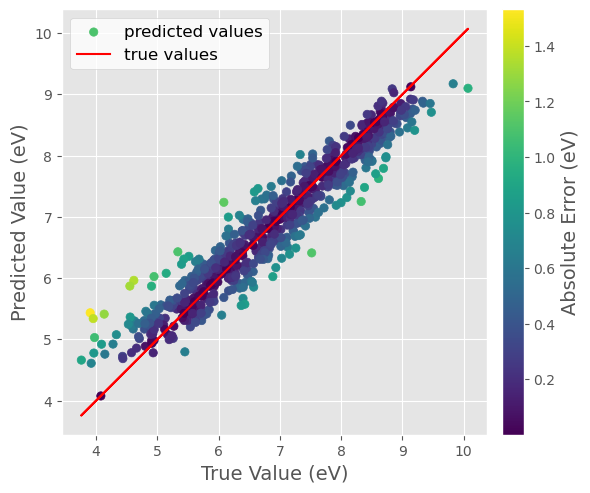

Training scores:
MAE = 0.3033
MSE = 0.1495
RMSE = 0.3867
r^2 = 0.9067


In [5]:
plot_prediction(X_test, y_test, com, name='', model_name='',save='models/qm9small/com_gap_qm9small_plot.pdf', format='pdf')

# AL Query strategies

### Training

In [6]:
def al_loop_rnd(
    model,
    n_initial=7106,
    batch_size=5000,
    n_cycles=None,
    random_state=42,
    n_runs=1,
    save=None,
):
    '''
    Run a Random sampling active learning loop over a regression task.

    Args:
        model: Base estimator to train and wrap in a BaggingRegressor committee (sklearn-compatible regressor).
        n_initial: Number of randomly selected initial samples (int).
        batch_size: Number of samples to query and label per cycle (int).
        n_cycles: Number of AL cycles to run, if None runs until the pool is exhausted (int or None).
        random_state: rng seed (int).
        n_runs: Number of independent runs with different initial labeled sets (int).
        save: File path to save the combined results, if None file is not saved (str or None).

    Returns:
        pd.DataFrame of all runs concatenated into a single flat DataFrame, with 'run' and 'cycle' columns for grouping.
    '''
    rng = np.random.default_rng(random_state)
    run_seeds = rng.integers(0, 2**31, size=n_runs)

    all_histories = []

    for run in range(n_runs):
        run_seed = run_seeds[run]
        run_rng = np.random.default_rng(run_seed)

        print(f'\n{'='*60}')
        print(f'Run {run + 1}/{n_runs}  (seed={run_seed})')
        print(f'{'='*60}')
        
        # ── Label pool ─────────────────────────────────────────────────────────────────
        y_pool = np.full(len(X_train), MISSING_LABEL)
        initial_idx = rng.choice(len(X_train), size=n_initial, replace=False)
        y_pool[initial_idx] = y_train[initial_idx]
        
        # ── Query strategy ─────────────────────────────────────────────────────────────
        rnd = RandomSampling(random_state=random_state)
        
        # ── History ────────────────────────────────────────────────────────────────────
        history = {
            'run': [],
            'cycle': [],
            'n_labeled': [],
            'mae_test': [],
            'mse_test': [],
            'rmse_test': [],
            'r2_test': [],
            'mae_val': [],
            'mse_val': [],
            'rmse_val': [],
            'r2_val': [],
            'queried_idx': [],
        }
        
        reg = clone(model)
    
        if n_cycles is None:
            n_cycles = math.ceil((len(X_train)-n_initial)/batch_size) + 1
        
        # ── Active-learning loop ───────────────────────────────────────────────────────
        for cycle in range(n_cycles):
            labeled_idx = labeled_indices(y_pool)
            unlabeled_idx = unlabeled_indices(y_pool)
            n_labeled = len(labeled_indices(y_pool))           
        
            # 1. Train model
            reg.fit(X_train[labeled_idx], y_pool[labeled_idx])
        
            # 2. Record
            y_pred_test = reg.predict(X_test)
            y_pred_val = reg.predict(X_val)
            
            mae_test = mean_absolute_error(y_test, y_pred_test)
            mse_test = mean_squared_error(y_test, y_pred_test)
            rmse_test = root_mean_squared_error(y_test, y_pred_test)
            r2_test = r2_score(y_test, y_pred_test)
        
            mae_val = mean_absolute_error(y_val, y_pred_val)
            mse_val = mean_squared_error(y_val, y_pred_val)
            rmse_val = root_mean_squared_error(y_val, y_pred_val)
            r2_val = r2_score(y_val, y_pred_val)

            history['run'].append(run+1)
            history['cycle'].append(cycle+1)
            history['n_labeled'].append(n_labeled)
            history['mae_test'].append(mae_test)
            history['mse_test'].append(mse_test)
            history['rmse_test'].append(rmse_test)
            history['r2_test'].append(r2_test)
            history['mae_val'].append(mae_val)
            history['mse_val'].append(mse_val)
            history['rmse_val'].append(rmse_val)
            history['r2_val'].append(r2_val)

            if cycle == 0:
                history['queried_idx'].append(initial_idx.tolist())
            else:
                history['queried_idx'].append(query_idx.tolist())
                
            if len(unlabeled_idx) == 0:    
                print(
                    f'Cycle {cycle + 1:>2} | '
                    f'Labeled: {n_labeled:>5}/{len(X_train)} | '
                    f'MAE: {mae_test:.4f} Eh | '
                    f'RMSE: {rmse_test:.4f} Eh | '
                    f'R2: {r2_test:.4f} | '
                )
                print('All pool samples labeled.')
                break
                
            # 3. Query random samples
            query_idx = rnd.query(X=X_train, y=y_pool, batch_size=batch_size)
            
            y_pool[query_idx] = y_train[query_idx]
                
            print(
                f'Cycle {cycle + 1:>2} | '
                f'Labeled: {n_labeled:>5}/{len(X_train)} | '
                f'MAE: {mae_test:.4f} Eh | '
                f'RMSE: {rmse_test:.4f} Eh | '
                f'R2: {r2_test:.4f} | '
            )            
            
        print(f'\nDone. Final labeled count: {labeled_indices(y_pool).size}/{len(X_train)}')
        
        all_histories.append(history)

    df = pd.concat([pd.DataFrame(h) for h in all_histories], ignore_index=True)
    if save is not None:
        df.to_csv(save, index=False)
    
    return df

In [7]:
def al_loop_qbc(
    model,
    n_initial=7106,
    batch_size=5000,
    n_cycles=None,
    random_state=42,
    n_runs=1,
    save=None,
):
    '''
    Run a Uncertainty sampling (Query-by-Committee with heterogeneous models) active learning loop over a regression task.

    Args:
        models: Committee models of several base estimators (sklearn VotingRegressor).
        n_initial: Number of randomly selected initial samples (int).
        batch_size: Number of samples to query and label per cycle (int).
        n_cycles: Number of AL cycles to run, if None runs until the pool is exhausted (int or None).
        random_state: rng seed (int).
        n_runs: Number of independent runs with different initial labeled sets (int).
        save: File path to save the combined results, if None file is not saved (str or None).

    Returns:
        pd.DataFrame of all runs concatenated into a single flat DataFrame, with 'run' and 'cycle' columns for grouping.
    '''
    rng = np.random.default_rng(random_state)
    run_seeds = rng.integers(0, 2**31, size=n_runs)

    all_histories = []

    for run in range(n_runs):
        run_seed = run_seeds[run]
        run_rng = np.random.default_rng(run_seed)

        print(f'\n{'='*60}')
        print(f'Run {run + 1}/{n_runs}  (seed={run_seed})')
        print(f'{'='*60}')
        
        # ── Label pool ─────────────────────────────────────────────────────────────────
        y_pool = np.full(len(X_train), MISSING_LABEL)
        initial_idx = rng.choice(len(X_train), size=n_initial, replace=False)
        y_pool[initial_idx] = y_train[initial_idx]
        
        # ── Query strategy ─────────────────────────────────────────────────────────────
        qbc = QueryByCommittee(random_state=random_state)
        
        # ── History ────────────────────────────────────────────────────────────────────
        history = {
            'run': [],
            'cycle': [],
            'n_labeled': [],
            'mae_test': [],
            'mse_test': [],
            'rmse_test': [],
            'r2_test': [],
            'mae_val': [],
            'mse_val': [],
            'rmse_val': [],
            'r2_val': [],
            'mean_uncertainty': [],   # avg utility score of queried batch
            'max_uncertainty': [],   # highest utility in the queried batch
            'queried_idx': [],
        }
        
        reg = clone(model)
    
        if n_cycles is None:
            n_cycles = math.ceil((len(X_train)-n_initial)/batch_size) + 1
        
        # ── Active-learning loop ───────────────────────────────────────────────────────
        for cycle in range(n_cycles):
            labeled_idx = labeled_indices(y_pool)
            unlabeled_idx = unlabeled_indices(y_pool)
            n_labeled = len(labeled_indices(y_pool))           
        
            reg.fit(X_train[labeled_idx], y_pool[labeled_idx])
            
            # 1. Train committee
            ensemble = SklearnRegressor(
                estimator=reg, random_state=random_state
            )
        
            # 2. Record
            y_pred_test = reg.predict(X_test)
            y_pred_val = reg.predict(X_val)
            
            mae_test = mean_absolute_error(y_test, y_pred_test)
            mse_test = mean_squared_error(y_test, y_pred_test)
            rmse_test = root_mean_squared_error(y_test, y_pred_test)
            r2_test = r2_score(y_test, y_pred_test)
        
            mae_val = mean_absolute_error(y_val, y_pred_val)
            mse_val = mean_squared_error(y_val, y_pred_val)
            rmse_val = root_mean_squared_error(y_val, y_pred_val)
            r2_val = r2_score(y_val, y_pred_val)

            history['run'].append(run+1)
            history['cycle'].append(cycle+1)
            history['n_labeled'].append(n_labeled)
            history['mae_test'].append(mae_test)
            history['mse_test'].append(mse_test)
            history['rmse_test'].append(rmse_test)
            history['r2_test'].append(r2_test)
            history['mae_val'].append(mae_val)
            history['mse_val'].append(mse_val)
            history['rmse_val'].append(rmse_val)
            history['r2_val'].append(r2_val)

            if cycle == 0:
                history['queried_idx'].append(initial_idx.tolist())
            else:
                history['queried_idx'].append(query_idx.tolist())
            
            if len(unlabeled_idx) == 0:
                history['mean_uncertainty'].append(0.0)
                history['max_uncertainty'].append(0.0)
                    
                print(
                    f'Cycle {cycle + 1:>2} | '
                    f'Labeled: {n_labeled:>5}/{len(X_train)} | '
                    f'MAE: {mae_test:.4f} Eh | '
                    f'RMSE: {rmse_test:.4f} Eh | '
                    f'R2: {r2_test:.4f} | '
                    f'Uncertainty — mean: {0:.4f} Eh  '
                    f'max: {0:.4f} Eh'
                )
                print('All pool samples labeled.')
                break
                
            # 3. Query most uncertain samples
            query_idx, utilities = call_func(
                qbc.query,
                X=X_train,
                y=y_pool,
                reg=reg,
                ensemble=ensemble,
                fit_ensemble=True,
                batch_size=batch_size,
                return_utilities=True,
            )
            
            y_pool[query_idx] = y_train[query_idx]            
            
            queried_utilities = utilities[0, query_idx]  # shape (1, n_pool)        
            
            history['mean_uncertainty'].append(queried_utilities.mean())
            history['max_uncertainty'].append(queried_utilities.max())
                
            print(
                f'Cycle {cycle + 1:>2} | '
                f'Labeled: {n_labeled:>5}/{len(X_train)} | '
                f'MAE: {mae_test:.4f} Eh | '
                f'RMSE: {rmse_test:.4f} Eh | '
                f'R2: {r2_test:.4f} | '
                f'Uncertainty — mean: {np.sqrt(queried_utilities.mean()):.4f} Eh  '
                f'max: {np.sqrt(queried_utilities.max()):.4f} Eh'
            )

            
            
        print(f'\nDone. Final labeled count: {labeled_indices(y_pool).size}/{len(X_train)}')
        
        all_histories.append(history)

    df = pd.concat([pd.DataFrame(h) for h in all_histories], ignore_index=True)
    if save is not None:
        df.to_csv(save, index=False)
        
    del reg
    del all_histories
    del history
    
    return df

In [8]:
def al_loop_div(
    model,
    n_initial=7106,
    batch_size=5000,
    n_cycles=None,
    random_state=42,
    n_runs=1,
    save=None,
):
    '''
    Run a Diversity sampling (Tanimoto distance) active learning loop over a regression task.

    Args:
        model: Base estimator to train and wrap in a BaggingRegressor committee (sklearn-compatible regressor).
        n_initial: Number of randomly selected initial samples (int).
        batch_size: Number of samples to query and label per cycle (int).
        n_cycles: Number of AL cycles to run, if None runs until the pool is exhausted (int or None).
        random_state: rng seed (int).
        n_runs: Number of independent runs with different initial labeled sets (int).
        save: File path to save the combined results, if None file is not saved (str or None).

    Returns:
        pd.DataFrame of all runs concatenated into a single flat DataFrame, with 'run' and 'cycle' columns for grouping.
    '''
    rng = np.random.default_rng(random_state)
    run_seeds = rng.integers(0, 2**31, size=n_runs)

    all_histories = []

    X_embeddings = X_train[:,:len(qm9_features)]
    
    for run in range(n_runs):
        run_seed = run_seeds[run]
        run_rng = np.random.default_rng(run_seed)

        print(f'\n{'='*60}')
        print(f'Run {run + 1}/{n_runs}  (seed={run_seed})')
        print(f'{'='*60}')
        
        # ── Label pool ─────────────────────────────────────────────────────────────────
        y_pool = np.full(len(X_train), MISSING_LABEL)
        initial_idx = rng.choice(len(X_train), size=n_initial, replace=False)
        y_pool[initial_idx] = y_train[initial_idx]

        # ── Query strategy ─────────────────────────────────────────────────────────────
        qs = TypiClust(missing_label=MISSING_LABEL, random_state=random_state)
        
        # ── History ────────────────────────────────────────────────────────────────────
        history = {
            'run': [],
            'cycle': [],
            'n_labeled': [],
            'mae_test': [],
            'mse_test': [],
            'rmse_test': [],
            'r2_test': [],
            'mae_val': [],
            'mse_val': [],
            'rmse_val': [],
            'r2_val': [],
            'queried_idx': [],
        }
        
        reg = clone(model)
    
        if n_cycles is None:
            n_cycles = math.ceil((len(X_train)-n_initial)/batch_size) + 1
        
        # ── Active-learning loop ───────────────────────────────────────────────────────
        for cycle in range(n_cycles):
            labeled_idx = labeled_indices(y_pool)
            unlabeled_idx = unlabeled_indices(y_pool)
            n_labeled = len(labeled_indices(y_pool))           
        
            # 1. Train model
            reg.fit(X_train[labeled_idx], y_pool[labeled_idx])
        
            # 2. Record
            y_pred_test = reg.predict(X_test)
            y_pred_val = reg.predict(X_val)
            
            mae_test = mean_absolute_error(y_test, y_pred_test)
            mse_test = mean_squared_error(y_test, y_pred_test)
            rmse_test = root_mean_squared_error(y_test, y_pred_test)
            r2_test = r2_score(y_test, y_pred_test)
        
            mae_val = mean_absolute_error(y_val, y_pred_val)
            mse_val = mean_squared_error(y_val, y_pred_val)
            rmse_val = root_mean_squared_error(y_val, y_pred_val)
            r2_val = r2_score(y_val, y_pred_val)

            history['run'].append(run+1)
            history['cycle'].append(cycle+1)
            history['n_labeled'].append(n_labeled)
            history['mae_test'].append(mae_test)
            history['mse_test'].append(mse_test)
            history['rmse_test'].append(rmse_test)
            history['r2_test'].append(r2_test)
            history['mae_val'].append(mae_val)
            history['mse_val'].append(mse_val)
            history['rmse_val'].append(rmse_val)
            history['r2_val'].append(r2_val)

            if cycle == 0:
                history['queried_idx'].append(initial_idx.tolist())
            else:
                history['queried_idx'].append(query_idx.tolist())
            
            if len(unlabeled_idx) == 0:                    
                print(
                    f'Cycle {cycle + 1:>2} | '
                    f'Labeled: {n_labeled:>5}/{len(X_train)} | '
                    f'MAE: {mae_test:.4f} Eh | '
                    f'RMSE: {rmse_test:.4f} Eh | '
                    f'R2: {r2_test:.4f} | '
                )
                print('All pool samples labeled.')
                break
                
            # 3. Query random samples            
            query_idx = qs.query(
                X=X_embeddings,
                y=y_pool,
                candidates=unlabeled_idx,
                batch_size=batch_size,
            )
            
            y_pool[query_idx] = y_train[query_idx]

            print(
                f'Cycle {cycle + 1:>2} | '
                f'Labeled: {n_labeled:>5}/{len(X_train)} | '
                f'MAE: {mae_test:.4f} Eh | '
                f'RMSE: {rmse_test:.4f} Eh | '
                f'R2: {r2_test:.4f} | '
            )            
            
        print(f'\nDone. Final labeled count: {labeled_indices(y_pool).size}/{len(X_train)}')
        
        all_histories.append(history)

    df = pd.concat([pd.DataFrame(h) for h in all_histories], ignore_index=True)
    if save is not None:
        df.to_csv(save, index=False)

    del reg
    del all_histories
    del history
    
    return df

In [9]:
al_loop_rnd(com, n_runs=5, n_initial=356, batch_size=500, save='../al/com/qm9small/al_history_com_rnd_gap_qm9small.csv')


Run 1/5  (seed=191664964)
Cycle  1 | Labeled:   356/5356 | MAE: 0.0169 Eh | RMSE: 0.0217 Eh | R2: 0.7829 | 
Cycle  2 | Labeled:   856/5356 | MAE: 0.0145 Eh | RMSE: 0.0186 Eh | R2: 0.8400 | 
Cycle  3 | Labeled:  1356/5356 | MAE: 0.0133 Eh | RMSE: 0.0171 Eh | R2: 0.8645 | 
Cycle  4 | Labeled:  1856/5356 | MAE: 0.0123 Eh | RMSE: 0.0158 Eh | R2: 0.8853 | 
Cycle  5 | Labeled:  2356/5356 | MAE: 0.0122 Eh | RMSE: 0.0157 Eh | R2: 0.8858 | 
Cycle  6 | Labeled:  2856/5356 | MAE: 0.0117 Eh | RMSE: 0.0151 Eh | R2: 0.8942 | 
Cycle  7 | Labeled:  3356/5356 | MAE: 0.0115 Eh | RMSE: 0.0148 Eh | R2: 0.8988 | 
Cycle  8 | Labeled:  3856/5356 | MAE: 0.0113 Eh | RMSE: 0.0146 Eh | R2: 0.9019 | 
Cycle  9 | Labeled:  4356/5356 | MAE: 0.0113 Eh | RMSE: 0.0145 Eh | R2: 0.9029 | 
Cycle 10 | Labeled:  4856/5356 | MAE: 0.0110 Eh | RMSE: 0.0142 Eh | R2: 0.9072 | 
Cycle 11 | Labeled:  5356/5356 | MAE: 0.0111 Eh | RMSE: 0.0142 Eh | R2: 0.9067 | 
All pool samples labeled.

Done. Final labeled count: 5356/5356

Run 2/

,run,cycle,n_labeled,mae_test,mse_test,rmse_test,r2_test,mae_val,mse_val,rmse_val,r2_val,queried_idx
0,1,1,356,0.016878,0.000470,0.021685,0.782856,0.017794,0.000517,0.022748,0.768679,"[3111, 2883, 3763, 1081, 1726, 1877, 2346, 141..."
1,1,2,856,0.014546,0.000346,0.018611,0.840045,0.015542,0.000397,0.019930,0.822451,"[2049, 3789, 186, 4761, 2786, 481, 2832, 1503,..."
2,1,3,1356,0.013312,0.000293,0.017129,0.864516,0.014617,0.000346,0.018609,0.845200,"[3239, 3898, 5116, 3527, 2911, 4289, 1089, 725..."
3,1,4,1856,0.012321,0.000248,0.015763,0.885257,0.013647,0.000302,0.017377,0.865020,"[4247, 4987, 130, 1373, 393, 4193, 892, 3907, ..."
4,1,5,2356,0.012207,0.000247,0.015728,0.885773,0.013380,0.000290,0.017027,0.870412,"[318, 1384, 4254, 2532, 474, 870, 4184, 1063, ..."
5,1,6,2856,0.011676,0.000229,0.015136,0.894205,0.012869,0.000272,0.016502,0.878272,"[1819, 2764, 685, 5252, 4554, 293, 106, 583, 2..."
6,1,7,3356,0.011459,0.000219,0.014802,0.898825,0.012582,0.000259,0.016092,0.884246,"[4570, 3576, 1803, 5159, 1023, 1049, 2399, 723..."
7,1,8,3856,0.011321,0.000212,0.014577,0.901876,0.012327,0.000247,0.015704,0.889757,"[10, 4235, 3940, 3937, 1985, 2640, 2665, 3300,..."
8,1,9,4356,0.011267,0.000210,0.014500,0.902906,0.012060,0.000235,0.015322,0.895055,"[1851, 1192, 2897, 3101, 1664, 813, 5118, 289,..."
9,1,10,4856,0.011046,0.000201,0.014175,0.907212,0.011924,0.000228,0.015105,0.898006,"[3978, 1614, 3309, 958, 3845, 2421, 2819, 4696..."


In [10]:
al_loop_qbc(com, n_runs=5, n_initial=356, batch_size=500, save='../al/com/qm9small/al_history_com_unc_gap_qm9small.csv')


Run 1/5  (seed=191664964)
Cycle  1 | Labeled:   356/5356 | MAE: 0.0169 Eh | RMSE: 0.0217 Eh | R2: 0.7829 | Uncertainty — mean: 0.1301 Eh  max: 0.1683 Eh
Cycle  2 | Labeled:   856/5356 | MAE: 0.0153 Eh | RMSE: 0.0197 Eh | R2: 0.8213 | Uncertainty — mean: 0.1157 Eh  max: 0.1594 Eh
Cycle  3 | Labeled:  1356/5356 | MAE: 0.0131 Eh | RMSE: 0.0166 Eh | R2: 0.8721 | Uncertainty — mean: 0.1081 Eh  max: 0.1537 Eh
Cycle  4 | Labeled:  1856/5356 | MAE: 0.0126 Eh | RMSE: 0.0159 Eh | R2: 0.8839 | Uncertainty — mean: 0.1021 Eh  max: 0.1271 Eh
Cycle  5 | Labeled:  2356/5356 | MAE: 0.0120 Eh | RMSE: 0.0153 Eh | R2: 0.8925 | Uncertainty — mean: 0.0950 Eh  max: 0.1297 Eh
Cycle  6 | Labeled:  2856/5356 | MAE: 0.0117 Eh | RMSE: 0.0149 Eh | R2: 0.8976 | Uncertainty — mean: 0.0895 Eh  max: 0.1123 Eh
Cycle  7 | Labeled:  3356/5356 | MAE: 0.0116 Eh | RMSE: 0.0146 Eh | R2: 0.9014 | Uncertainty — mean: 0.0845 Eh  max: 0.1155 Eh
Cycle  8 | Labeled:  3856/5356 | MAE: 0.0114 Eh | RMSE: 0.0145 Eh | R2: 0.9024 | Unc

,run,cycle,n_labeled,mae_test,mse_test,rmse_test,r2_test,mae_val,mse_val,rmse_val,r2_val,mean_uncertainty,max_uncertainty,queried_idx
0,1,1,356,0.016878,0.000470,0.021685,0.782856,0.017794,0.000517,0.022748,0.768679,0.016928,0.028334,"[3111, 2883, 3763, 1081, 1726, 1877, 2346, 141..."
1,1,2,856,0.015304,0.000387,0.019669,0.821350,0.016261,0.000436,0.020892,0.804889,0.013394,0.025400,"[958, 3584, 4599, 1144, 2317, 2551, 34, 927, 6..."
2,1,3,1356,0.013090,0.000277,0.016645,0.872055,0.014332,0.000333,0.018238,0.851313,0.011694,0.023619,"[1025, 2188, 1390, 4494, 2767, 5147, 4860, 202..."
3,1,4,1856,0.012576,0.000252,0.015859,0.883851,0.013873,0.000305,0.017477,0.863465,0.010415,0.016162,"[4192, 4683, 4178, 3679, 252, 2963, 3909, 394,..."
4,1,5,2356,0.012043,0.000233,0.015259,0.892474,0.013174,0.000278,0.016659,0.875949,0.009031,0.016810,"[2283, 4018, 3038, 450, 3149, 4168, 4637, 1826..."
5,1,6,2856,0.011747,0.000222,0.014888,0.897647,0.012755,0.000261,0.016154,0.883352,0.008003,0.012613,"[4395, 2454, 4844, 1939, 4194, 5048, 54, 4866,..."
6,1,7,3356,0.011579,0.000213,0.014609,0.901443,0.012385,0.000244,0.015609,0.891095,0.007133,0.013334,"[4409, 1438, 4258, 1054, 3611, 2254, 3971, 314..."
7,1,8,3856,0.011423,0.000211,0.014539,0.902390,0.012108,0.000234,0.015305,0.895292,0.005924,0.014004,"[151, 727, 2514, 1475, 242, 255, 4392, 4852, 3..."
8,1,9,4356,0.011213,0.000203,0.014244,0.906305,0.011804,0.000225,0.015007,0.899332,0.004817,0.009552,"[2021, 24, 2324, 867, 2644, 891, 1070, 2972, 7..."
9,1,10,4856,0.011036,0.000198,0.014068,0.908614,0.011732,0.000220,0.014847,0.901471,0.002833,0.006825,"[2759, 2741, 163, 4146, 3370, 303, 3895, 3331,..."


In [11]:
al_loop_div(com, n_runs=5, n_initial=356, batch_size=500, save='../al/com/qm9small/al_history_com_div_gap_qm9small.csv')


Run 1/5  (seed=191664964)
Cycle  1 | Labeled:   356/5356 | MAE: 0.0169 Eh | RMSE: 0.0217 Eh | R2: 0.7829 | 
Cycle  2 | Labeled:   856/5356 | MAE: 0.0148 Eh | RMSE: 0.0186 Eh | R2: 0.8399 | 
Cycle  3 | Labeled:  1356/5356 | MAE: 0.0136 Eh | RMSE: 0.0173 Eh | R2: 0.8626 | 
Cycle  4 | Labeled:  1856/5356 | MAE: 0.0133 Eh | RMSE: 0.0168 Eh | R2: 0.8704 | 
Cycle  5 | Labeled:  2356/5356 | MAE: 0.0126 Eh | RMSE: 0.0159 Eh | R2: 0.8830 | 
Cycle  6 | Labeled:  2856/5356 | MAE: 0.0124 Eh | RMSE: 0.0155 Eh | R2: 0.8884 | 
Cycle  7 | Labeled:  3356/5356 | MAE: 0.0121 Eh | RMSE: 0.0152 Eh | R2: 0.8933 | 
Cycle  8 | Labeled:  3856/5356 | MAE: 0.0116 Eh | RMSE: 0.0147 Eh | R2: 0.9002 | 
Cycle  9 | Labeled:  4356/5356 | MAE: 0.0112 Eh | RMSE: 0.0143 Eh | R2: 0.9056 | 
Cycle 10 | Labeled:  4856/5356 | MAE: 0.0112 Eh | RMSE: 0.0143 Eh | R2: 0.9053 | 
Cycle 11 | Labeled:  5356/5356 | MAE: 0.0111 Eh | RMSE: 0.0142 Eh | R2: 0.9067 | 
All pool samples labeled.

Done. Final labeled count: 5356/5356

Run 2/

,run,cycle,n_labeled,mae_test,mse_test,rmse_test,r2_test,mae_val,mse_val,rmse_val,r2_val,queried_idx
0,1,1,356,0.016878,0.000470,0.021685,0.782856,0.017794,0.000517,0.022748,0.768679,"[3111, 2883, 3763, 1081, 1726, 1877, 2346, 141..."
1,1,2,856,0.014776,0.000347,0.018621,0.839890,0.015408,0.000382,0.019546,0.829226,"[2260, 761, 3888, 1206, 1365, 1317, 5248, 264,..."
2,1,3,1356,0.013632,0.000298,0.017253,0.862551,0.014402,0.000328,0.018122,0.853196,"[4372, 1362, 67, 315, 5298, 552, 4561, 1488, 4..."
3,1,4,1856,0.013349,0.000281,0.016752,0.870405,0.013899,0.000305,0.017456,0.863788,"[1232, 859, 4444, 3658, 411, 4024, 2118, 4013,..."
4,1,5,2356,0.012636,0.000253,0.015916,0.883016,0.013221,0.000280,0.016733,0.874838,"[4738, 1915, 831, 1609, 1716, 2319, 1028, 2026..."
5,1,6,2856,0.012432,0.000242,0.015548,0.888374,0.012894,0.000263,0.016208,0.882568,"[1789, 455, 2784, 4065, 3105, 3035, 5125, 3147..."
6,1,7,3356,0.012054,0.000231,0.015198,0.893332,0.012651,0.000252,0.015871,0.887402,"[2853, 4967, 3921, 3943, 1401, 2978, 1790, 529..."
7,1,8,3856,0.011604,0.000216,0.014698,0.900242,0.012370,0.000244,0.015615,0.891003,"[1380, 1611, 294, 1456, 3690, 445, 4620, 759, ..."
8,1,9,4356,0.011242,0.000204,0.014299,0.905590,0.012076,0.000232,0.015240,0.896185,"[2760, 1936, 432, 4824, 1829, 560, 499, 3174, ..."
9,1,10,4856,0.011197,0.000205,0.014322,0.905283,0.011873,0.000225,0.015015,0.899224,"[693, 613, 4462, 3167, 4775, 1996, 3953, 2465,..."
